# HW 1 Part A: SIR model and hand-written ODE solvers

The SIR model (S, I, R are **counts** of people/ subjects):

$$\frac{dS}{dt}=-\beta SI,\qquad \frac{dI}{dt}=\beta SI-\gamma I,\qquad \frac{dR}{dt}=\gamma I$$

The model and solvers are in `epimodels.py`:

| function | role |
|---|---|
| `sir_rhs(t, y, params)` | the model: returns $[\dot S,\dot I,\dot R]$ |
| `euler_step` | Forward Euler, $y_{n+1}=y_n+h f(y_n)$, global error $O(h)$ |
| `rk4_step` | classical Runge–Kutta, global error $O(h^4)$ (**primary method**) |
| `simulate` | fixed-step loop from $t=0$ to $t_\text{end}$ |


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp   # verification only
from epimodels import sir_rhs, simulate

os.makedirs("figures", exist_ok=True)   # output folder for saved plots

## Parameters 

In [2]:
N      = 2000
y0     = np.array([1995.0, 5.0, 0.0])   # S(0), I(0), R(0)
params = {"beta": 0.125e-3,             # per person per day
          "gamma": 0.1}                 # per day
t_end  = 160                            # days
h      = 0.1                            # step size (days)

## Run both solvers

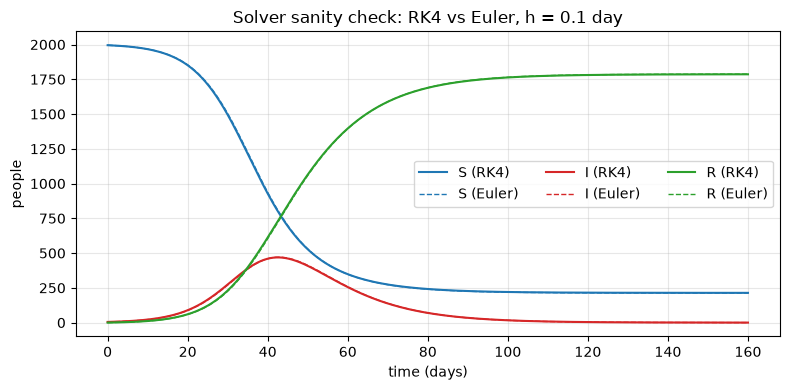

max |RK4 - Euler| at h=0.1: 10.716 people


In [3]:
t, Y_rk4   = simulate(sir_rhs, y0, t_end, h, params, method="rk4")
_, Y_euler = simulate(sir_rhs, y0, t_end, h, params, method="euler")

fig, ax = plt.subplots(figsize=(8, 4))
for k, (name, c) in enumerate(zip("SIR", ["tab:blue", "tab:red", "tab:green"])):
    ax.plot(t, Y_rk4[:, k], color=c, label=f"{name} (RK4)")
    ax.plot(t, Y_euler[:, k], color=c, ls="--", lw=1, label=f"{name} (Euler)")
ax.set_xlabel("time (days)"); ax.set_ylabel("people")
ax.set_title(f"Solver sanity check: RK4 vs Euler, h = {h} day")
ax.legend(ncol=3); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("figures/partA_rk4_vs_euler.png", dpi=150); plt.show()
print(f"max |RK4 - Euler| at h={h}: {np.abs(Y_rk4 - Y_euler).max():.3f} people")

## Check 1 Conservation of population
Since $\dot S+\dot I+\dot R=0$, $S+I+R=N$ for all $t$. Every Runge–Kutta step adds only weighted sums of $f$,
whose components sum to zero, so both solvers should keep $N$ to **round-off** (~1e-12).
This check detects coding errors (wrong sign, missing term); it says nothing about accuracy.

In [4]:
for name, Y in [("RK4", Y_rk4), ("Euler", Y_euler)]:
    drift = np.abs(Y.sum(axis=1) - N).max()
    print(f"{name:5s}: max |S+I+R - N| = {drift:.2e} people  (relative {drift/N:.1e})")
    assert drift / N < 1e-10

RK4  : max |S+I+R - N| = 3.18e-12 people  (relative 1.6e-15)
Euler: max |S+I+R - N| = 2.73e-12 people  (relative 1.4e-15)


## Check 2 Nonnegativity
A population cannot be negative. With Euler, $S_{n+1}=S_n(1-h\beta I_n)$, so $S$ stays positive while $h\beta I_n<1$
and $I_{n+1}=I_n(1+h(\beta S_n-\gamma))$ stays positive while $h\gamma<1$.

In [5]:
for name, Y in [("RK4", Y_rk4), ("Euler", Y_euler)]:
    print(f"{name:5s}: min over all compartments = {Y.min():.4f}")
    assert Y.min() >= 0

print(f"Euler safety margins at h={h}: max h*beta*I = {h*params['beta']*Y_euler[:,1].max():.4f},"
      f"  h*gamma = {h*params['gamma']:.2f}  (both must be < 1)")

# Stress test: how large must h be before Euler breaks?
for h_big in [1, 5, 10, 16]:
    _, Yb = simulate(sir_rhs, y0, t_end, h_big, params, method="euler")
    print(f"Euler, h = {h_big:>2} days: min value = {Yb.min():9.2f}  ->  {'OK' if Yb.min() >= 0 else 'NEGATIVE'}")

RK4  : min over all compartments = 0.0000
Euler: min over all compartments = 0.0000
Euler safety margins at h=0.1: max h*beta*I = 0.0059,  h*gamma = 0.01  (both must be < 1)
Euler, h =  1 days: min value =      0.00  ->  OK
Euler, h =  5 days: min value =      0.00  ->  OK
Euler, h = 10 days: min value =      0.00  ->  OK
Euler, h = 16 days: min value =   -499.54  ->  NEGATIVE


## Check 3 – Analytical special cases
**(a) No infection, $I(0)=0$:** nothing should ever change.

**(b) No transmission, $\beta=0$:** $\dot I=-\gamma I$, so exactly
$I(t)=I_0e^{-\gamma t}$, $R(t)=R_0+I_0(1-e^{-\gamma t})$, $S$ constant.

In [6]:
# (a) disease-free state is an equilibrium
y_free = np.array([2000.0, 0.0, 0.0])
for m in ["rk4", "euler"]:
    _, Yf = simulate(sir_rhs, y_free, t_end, h, params, method=m)
    print(f"(a) {m:5s}: max change from initial state = {np.abs(Yf - y_free).max():.1e}")
    assert np.allclose(Yf, y_free)

# (b) pure recovery has a closed-form solution
p0 = {"beta": 0.0, "gamma": params["gamma"]}
I_exact = y0[1] * np.exp(-p0["gamma"] * t)
R_exact = y0[2] + y0[1] * (1 - np.exp(-p0["gamma"] * t))
for m in ["rk4", "euler"]:
    _, Yb = simulate(sir_rhs, y0, t_end, h, p0, method=m)
    err = max(np.abs(Yb[:, 1] - I_exact).max(), np.abs(Yb[:, 2] - R_exact).max())
    print(f"(b) {m:5s}: max error vs exact solution = {err:.2e} people, S drift = {np.abs(Yb[:,0]-y0[0]).max():.1e}")

(a) rk4  : max change from initial state = 0.0e+00
(a) euler: max change from initial state = 0.0e+00
(b) rk4  : max error vs exact solution = 1.55e-10 people, S drift = 0.0e+00
(b) euler: max error vs exact solution = 9.24e-03 people, S drift = 0.0e+00


## Check 4 Convergence order and choice of h
Reference: `solve_ivp` (DOP853, rtol = atol = 1e-12) evaluated at whole days.
Error $E(h)=\max$ over days and compartments of $|y_h-y_\text{ref}|$. If $E\propto h^p$, halving $h$ divides $E$ by $2^p$:
we expect $p\approx1$ (Euler) and $p\approx4$ (RK4).

A second, **scipy-free** estimate (Richardson/self-convergence) uses only our solver:
$p\approx\log_2\frac{|y_h-y_{h/2}|}{|y_{h/2}-y_{h/4}|}$.

In [7]:
days = np.arange(0, t_end + 1)
ref = solve_ivp(lambda tt, yy: sir_rhs(tt, yy, params), (0, t_end), y0,
                method="DOP853", rtol=1e-12, atol=1e-12, t_eval=days).y.T

def on_days(t, Y):
    idx = np.searchsorted(t, days - 1e-9)       # rows at whole days
    return Y[idx]

hs = [1.0, 0.5, 0.25, 0.125, 0.0625]
errs = {"euler": [], "rk4": []}
for m in errs:
    for hh in hs:
        tt, YY = simulate(sir_rhs, y0, t_end, hh, params, method=m)
        errs[m].append(np.abs(on_days(tt, YY) - ref).max())

print(f"{'h (days)':>9} | {'Euler error':>12} {'order':>6} | {'RK4 error':>12} {'order':>6}")
for i, hh in enumerate(hs):
    pe = np.log2(errs['euler'][i-1] / errs['euler'][i]) if i else np.nan
    pr = np.log2(errs['rk4'][i-1]   / errs['rk4'][i])   if i else np.nan
    print(f"{hh:9.4f} | {errs['euler'][i]:12.3e} {pe:6.2f} | {errs['rk4'][i]:12.3e} {pr:6.2f}")

 h (days) |  Euler error  order |    RK4 error  order
   1.0000 |    1.066e+02    nan |    4.134e-03    nan
   0.5000 |    5.344e+01   1.00 |    2.730e-04   3.92
   0.2500 |    2.677e+01   1.00 |    1.754e-05   3.96
   0.1250 |    1.339e+01   1.00 |    1.112e-06   3.98
   0.0625 |    6.696e+00   1.00 |    7.033e-08   3.98


In [8]:
# Self-convergence (no scipy): compare h, h/2, h/4 at whole days
for m in ["euler", "rk4"]:
    sols = [on_days(*simulate(sir_rhs, y0, t_end, hh, params, method=m)) for hh in [0.2, 0.1, 0.05]]
    p = np.log2(np.abs(sols[0] - sols[1]).max() / np.abs(sols[1] - sols[2]).max())
    print(f"{m:5s}: observed order from h = 0.2, 0.1, 0.05 -> p = {p:.2f}")

euler: observed order from h = 0.2, 0.1, 0.05 -> p = 1.00
rk4  : observed order from h = 0.2, 0.1, 0.05 -> p = 3.98


rk4  , h = 0.1: max error vs solve_ivp = 4.57e-07 people


euler, h = 0.1: max error vs solve_ivp = 1.07e+01 people


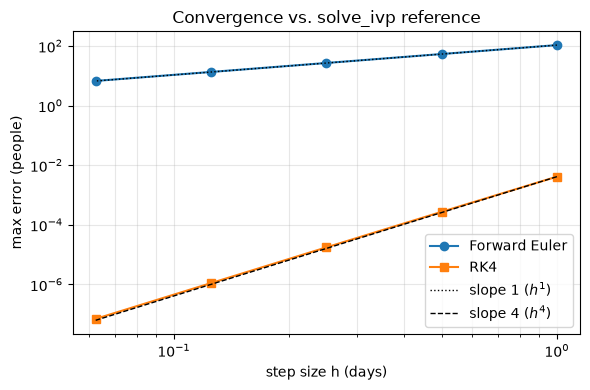

In [9]:
# Error at the chosen h = 0.1 versus the reference
for m in ["rk4", "euler"]:
    tt, YY = simulate(sir_rhs, y0, t_end, 0.1, params, method=m)
    print(f"{m:5s}, h = 0.1: max error vs solve_ivp = {np.abs(on_days(tt, YY) - ref).max():.2e} people")

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(hs, errs["euler"], "o-", label="Forward Euler")
ax.loglog(hs, errs["rk4"], "s-", label="RK4")
hh = np.array(hs)
ax.loglog(hh, errs["euler"][0] * hh / hh[0], "k:", lw=1, label=r"slope 1 ($h^1$)")
ax.loglog(hh, errs["rk4"][0] * (hh / hh[0])**4, "k--", lw=1, label=r"slope 4 ($h^4$)")
ax.set_xlabel("step size h (days)"); ax.set_ylabel("max error (people)")
ax.set_title("Convergence vs. solve_ivp reference"); ax.legend(); ax.grid(alpha=.3, which="both")
plt.tight_layout(); plt.savefig("figures/partA_convergence.png", dpi=150); plt.show()

## Summary
* Both solvers conserve $N$ to round-off and stay nonnegative at $h=0.1$ day
* Both reproduce the analytical special cases
* Observed orders match theory (≈1 for Euler, ≈4 for RK4), so the solvers are implemented correctly.
* At $h=0.1$ day, RK4 is accurate to far below one person, so it is used for Parts B–E; Euler at the same $h$ is off by several people